# Problema 1 - Regressão Linear Múltipla para previsão de produção de energia em uma Usina de Ciclo Combinado (UCI CCPP).
.


In [18]:
from pathlib import Path


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------------------------
# Configurações gerais
# ----------------------------------------------------------------------------
BASE = Path.cwd()  # abra o notebook DENTRO da pasta do problema (ao lado de dados/)
ARQ_DADOS = BASE / "dados" / "Folds5x2_pp.csv" #repositório disponibiizado
PASTA_FIG = BASE / "figuras"
PASTA_FIG.mkdir(exist_ok=True)

SEED = 42  # semente fixa -> resultados reproduzíveis
FEATURES = ["AT", "V", "AP", "RH"]  # variáveis independentes
ALVO = "PE"  # variável dependente (MW)

DESCRICAO = {
    "AT": "Temperatura ambiente (°C)",
    "V": "Vácuo de escape (cm Hg)",
    "AP": "Pressão ambiente (mbar)",
    "RH": "Umidade relativa (%)",
    "PE": "Potência elétrica líquida (MW)",
}


def titulo(texto):
    """Imprime um cabeçalho para separar as seções na saída do terminal."""
    print("\n" + "=" * 78)
    print(texto)
    print("=" * 78)


def rmse(y_real, y_prev):
    """Raiz do erro quadrático médio (mesma unidade do alvo: MW)."""
    return float(np.sqrt(mean_squared_error(y_real, y_prev)))

In [19]:
## 0. CARREGAMENTO E INSPEÇÃO DOS DADOS

In [20]:
titulo("0. Carregamento e inspeção dos dados")

df = pd.read_csv(ARQ_DADOS)
print(f"Formato (linhas, colunas): {df.shape}")
print("\nPrimeiras linhas:")
print(df.head())
print("\nTipos de dados:")
print(df.dtypes)
print("\nEstatísticas descritivas:")
print(df.describe().round(2).T)

n_faltantes = df.isna().sum()
print("\nValores ausentes por coluna:")
print(n_faltantes)
print(f"\nLinhas duplicadas (valores idênticos em todas as colunas): {df.duplicated().sum()}")


0. Carregamento e inspeção dos dados
Formato (linhas, colunas): (9568, 5)

Primeiras linhas:
      AT      V       AP     RH      PE
0   8.34  40.77  1010.84  90.01  480.48
1  23.64  58.49  1011.40  74.20  445.75
2  29.74  56.90  1007.15  41.91  438.76
3  19.07  49.69  1007.22  76.79  453.09
4  11.80  40.66  1017.13  97.20  464.43

Tipos de dados:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Estatísticas descritivas:
     count     mean    std     min      25%      50%      75%      max
AT  9568.0    19.65   7.45    1.81    13.51    20.34    25.72    37.11
V   9568.0    54.31  12.71   25.36    41.74    52.08    66.54    81.56
AP  9568.0  1013.26   5.94  992.89  1009.10  1012.94  1017.26  1033.30
RH  9568.0    73.31  14.60   25.56    63.33    74.97    84.83   100.16
PE  9568.0   454.37  17.07  420.26   439.75   451.55   468.43   495.76

Valores ausentes por coluna:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Linhas duplicadas (valores i

## PRÉ-PROCESSAMENTO (parte 1): divisão treino/teste

A divisão é feita ANTES de ajustar o imputador e o padronizador. Assim, a  
média/desvio padrão usados na padronização vêm só do treino. Se usássemos o  
conjunto todo, informação do teste "vazaria" para o treino (data leakage).

In [21]:
X = df[FEATURES]
y = df[ALVO]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f"\nTreino: {X_treino.shape[0]} amostras ({X_treino.shape[0] / len(df):.0%})")
print(f"Teste : {X_teste.shape[0]} amostras ({X_teste.shape[0] / len(df):.0%})")


Treino: 7654 amostras (80%)
Teste : 1914 amostras (20%)


## TAREFA 1 - Correlação entre as variáveis independentes e a variável alvo


TAREFA 1 - Correlação de AT, V, AP, RH com PE
    Pearson  Spearman  |Pearson|
AT  -0.9481   -0.9444     0.9481
V   -0.8698   -0.8837     0.8698
AP   0.5184    0.5425     0.5184
RH   0.3898    0.3896     0.3898

Ranking de influência linear (maior |r| primeiro): ['AT', 'V', 'AP', 'RH']


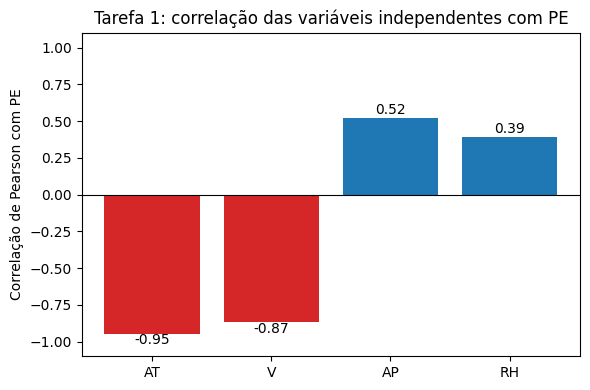

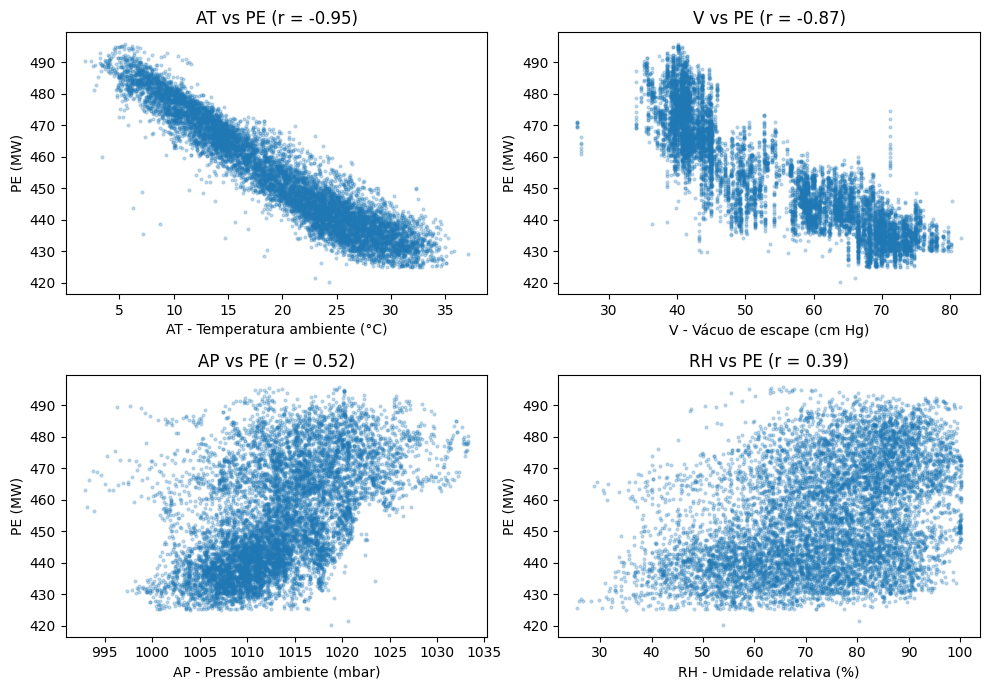

In [22]:
titulo("TAREFA 1 - Correlação de AT, V, AP, RH com PE")
#hipóteses
# Correlação de Pearson (mede dependência LINEAR; é a que se relaciona
# diretamente com a regressão linear). Spearman (por postos) serve como
# checagem de robustez: se divergir muito, há relação não linear/outliers.
corr_pearson = df[FEATURES + [ALVO]].corr(method="pearson")[ALVO].drop(ALVO)
corr_spearman = df[FEATURES + [ALVO]].corr(method="spearman")[ALVO].drop(ALVO)

tab1 = pd.DataFrame(
    {
        "Pearson": corr_pearson,
        "Spearman": corr_spearman,
        "|Pearson|": corr_pearson.abs(),
    }
).sort_values("|Pearson|", ascending=False)
print(tab1.round(4))
print("\nRanking de influência linear (maior |r| primeiro):", list(tab1.index))

# Figura 1a: barras com a correlação de cada variável com PE
fig, ax = plt.subplots(figsize=(6, 4))
ordem = tab1.index
cores = ["tab:red" if v < 0 else "tab:blue" for v in tab1.loc[ordem, "Pearson"]]
ax.bar(ordem, tab1.loc[ordem, "Pearson"], color=cores)
for i, v in enumerate(tab1.loc[ordem, "Pearson"]):
    ax.text(i, v + (0.03 if v >= 0 else -0.07), f"{v:.2f}", ha="center")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-1.1, 1.1)
ax.set_ylabel("Correlação de Pearson com PE")
ax.set_title("Tarefa 1: correlação das variáveis independentes com PE")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_correlacao_com_PE.png", dpi=150)
plt.show()

# Figura 1b: diagramas de dispersão de cada variável contra PE
fig, eixos = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(eixos.ravel(), FEATURES):
    ax.scatter(df[col], df[ALVO], s=4, alpha=0.25)
    ax.set_xlabel(f"{col} - {DESCRICAO[col]}")
    ax.set_ylabel("PE (MW)")
    ax.set_title(f"{col} vs PE (r = {corr_pearson[col]:.2f})")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t1_dispersao_features_vs_PE.png", dpi=150)
plt.show()

# A variável que apresenta maior influência na produção de energia é a temperatura ambiente (AT), pois possui a maior correlação em valor absoluto com a variável dependente (PE), indicando forte relação inversa. Isso significa que, à medida que a temperatura aumenta, a produção de energia tende a diminuir

## TAREFA 2 - Correlação entre as variáveis independentes (multicolinearidade)


TAREFA 2 - Correlação entre AT, V, AP, RH (multicolinearidade)
Matriz de correlação de Pearson entre as variáveis independentes:
        AT       V      AP      RH
AT  1.0000  0.8441 -0.5075 -0.5425
V   0.8441  1.0000 -0.4135 -0.3122
AP -0.5075 -0.4135  1.0000  0.0996
RH -0.5425 -0.3122  0.0996  1.0000

Pares ordenados por |r|:
  AT x V: r = +0.8441
  AT x RH: r = -0.5425
  AT x AP: r = -0.5075
  V x AP: r = -0.4135
  V x RH: r = -0.3122
  AP x RH: r = +0.0996


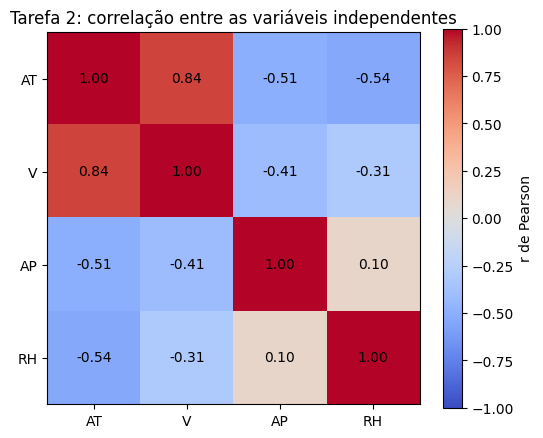


VIF de cada variável independente:
  AT: 5.98
  V: 3.94
  AP: 1.45
  RH: 1.71


In [23]:
titulo("TAREFA 2 - Correlação entre AT, V, AP, RH (multicolinearidade)")

matriz_corr = df[FEATURES].corr(method="pearson")
print("Matriz de correlação de Pearson entre as variáveis independentes:")
print(matriz_corr.round(4))

# Lista dos pares (sem repetir) ordenados por |r|
pares = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        pares.append((a, b, matriz_corr.loc[a, b]))
pares.sort(key=lambda t: abs(t[2]), reverse=True)
print("\nPares ordenados por |r|:")
for a, b, r in pares:
    print(f"  {a} x {b}: r = {r:+.4f}")

# Figura 2: mapa de calor da matriz de correlação (com os valores anotados)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(matriz_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{matriz_corr.values[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="r de Pearson")
ax.set_title("Tarefa 2: correlação entre as variáveis independentes")
fig.tight_layout()
fig.savefig(PASTA_FIG / "t2_matriz_correlacao_features.png", dpi=150)
plt.show()

# VIF (Variance Inflation Factor): quantifica a multicolinearidade.
#   VIF_j = 1 / (1 - R2_j), em que R2_j vem de regredir a variável j nas demais.
# Regra prática: VIF > 5 (ou > 10) indica colinearidade preocupante.
vif = {}
for col in FEATURES:
    outras = [c for c in FEATURES if c != col]
    r2_j = LinearRegression().fit(df[outras], df[col]).score(df[outras], df[col])
    vif[col] = 1.0 / (1.0 - r2_j)
print("\nVIF de cada variável independente:")
for col, v in vif.items():
    print(f"  {col}: {v:.2f}")

## PRÉ-PROCESSAMENTO (parte 2) + TAREFA 3 - Modelo de regressão linear múltipla

In [24]:
titulo("TAREFA 3 - Regressão linear múltipla (treino 80% / teste 20%)")

# Pipeline = imputação -> padronização -> regressão linear.
#   * SimpleImputer(median): trata valores ausentes (neste dataset não há,
#     mas o passo fica no pipeline para o código ser robusto).
#   * StandardScaler: z = (x - média) / desvio, com média e desvio calculados
#     apenas no treino. Deixa as variáveis na mesma escala (AP ~ 1000 mbar
#     contra AT ~ 20 °C) e permite comparar os coeficientes entre si.
modelo = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression(),
)
modelo.fit(X_treino, y_treino)

imputador, escalador, reg = modelo.steps[0][1], modelo.steps[1][1], modelo.steps[2][1]

# Coeficientes na escala padronizada (comparáveis entre si)
coef_padr = reg.coef_
interc_padr = reg.intercept_

# Coeficientes convertidos para as unidades originais (interpretação física):
#   PE = b0 + sum(bj * xj)  com  xj em unidades originais
#   bj_orig = bj_padr / desvio_j
#   b0_orig = b0_padr - sum(bj_padr * media_j / desvio_j)
coef_orig = coef_padr / escalador.scale_
interc_orig = interc_padr - np.sum(coef_padr * escalador.mean_ / escalador.scale_)

tab_coef = pd.DataFrame(
    {
        "coef_padronizado": coef_padr,
        "coef_unidade_original": coef_orig,
        "unidade": ["MW/°C", "MW/cmHg", "MW/mbar", "MW/%"],
    },
    index=FEATURES,
)
print(tab_coef.round(4))
print(f"\nIntercepto (escala padronizada): {interc_padr:.4f}  (= média de PE no treino)")
print(f"Intercepto (unidades originais): {interc_orig:.4f} MW")
print(
    "\nEquação do modelo (unidades originais):\n"
    f"  PE = {interc_orig:.3f} "
    + " ".join(f"{c:+.4f}*{f}" for f, c in zip(FEATURES, coef_orig))
)

# Conferência: a equação em unidades originais deve gerar exatamente as mesmas
# previsões do pipeline (que padroniza internamente).
prev_equacao = interc_orig + X_teste.to_numpy() @ coef_orig
assert np.allclose(prev_equacao, modelo.predict(X_teste)), "equação != pipeline"
print("Conferência OK: a equação em unidades originais reproduz as previsões do pipeline.")

# Conferência: solução analítica (equação normal), como nos slides da disciplina
#   Phi = (X^T X)^(-1) X^T y   -> aqui resolvida com np.linalg.solve
X_tr_pad = escalador.transform(imputador.transform(X_treino))
X_design = np.column_stack([np.ones(len(X_tr_pad)), X_tr_pad])  # coluna de 1s = intercepto
phi = np.linalg.solve(X_design.T @ X_design, X_design.T @ y_treino.to_numpy())
print("\nConferência pela equação normal (deve coincidir com o scikit-learn):")
print(f"  intercepto: normal={phi[0]:.6f} | sklearn={interc_padr:.6f}")
for f, a, b in zip(FEATURES, phi[1:], coef_padr):
    print(f"  {f}: normal={a:.6f} | sklearn={b:.6f}")
assert np.allclose(phi[1:], coef_padr) and np.isclose(phi[0], interc_padr)


TAREFA 3 - Regressão linear múltipla (treino 80% / teste 20%)
    coef_padronizado  coef_unidade_original  unidade
AT          -14.7708                -1.9770    MW/°C
V            -2.9847                -0.2348  MW/cmHg
AP            0.3441                 0.0583  MW/mbar
RH           -2.3038                -0.1581     MW/%

Intercepto (escala padronizada): 454.4029  (= média de PE no treino)
Intercepto (unidades originais): 458.5962 MW

Equação do modelo (unidades originais):
  PE = 458.596 -1.9770*AT -0.2348*V +0.0583*AP -0.1581*RH
Conferência OK: a equação em unidades originais reproduz as previsões do pipeline.

Conferência pela equação normal (deve coincidir com o scikit-learn):
  intercepto: normal=454.402895 | sklearn=454.402895
  AT: normal=-14.770778 | sklearn=-14.770778
  V: normal=-2.984744 | sklearn=-2.984744
  AP: normal=0.344064 | sklearn=0.344064
  RH: normal=-2.303769 | sklearn=-2.303769


## TAREFA 4 - Avaliação do desempenho (R², RMSE, MAE)


TAREFA 4 - Avaliação: R2, RMSE e MAE
                                   R2  RMSE (MW)  MAE (MW)
Treino                         0.9280     4.5894    3.6474
Teste                          0.9315     4.4281    3.5434
Linha de base (média) - teste -0.0001    16.9169   14.7057

Amplitude de PE no dataset: 75.50 MW (420.26 a 495.76)
Desvio padrão de PE: 17.07 MW | média de PE: 454.37 MW
RMSE (teste) / amplitude: 5.87%
MAE  (teste) / média    : 0.78%

R2 em validação cruzada 5-fold (treino): [0.929  0.9212 0.9272 0.927  0.935 ]
  média = 0.9279 | desvio padrão = 0.0044

Resíduos no teste:
  média = -0.320 MW | desvio padrão = 4.417 MW
  |erro| máximo = 28.41 MW
  % das previsões com |erro| <= 5 MW: 75.1%
  % das previsões com |erro| <= 10 MW: 98.2%

Experimento: removendo V (colinear com AT)
  R2 = 0.9238 | RMSE = 4.670 MW | MAE = 3.708 MW
  (com as 4 variáveis: R2 = 0.9315)


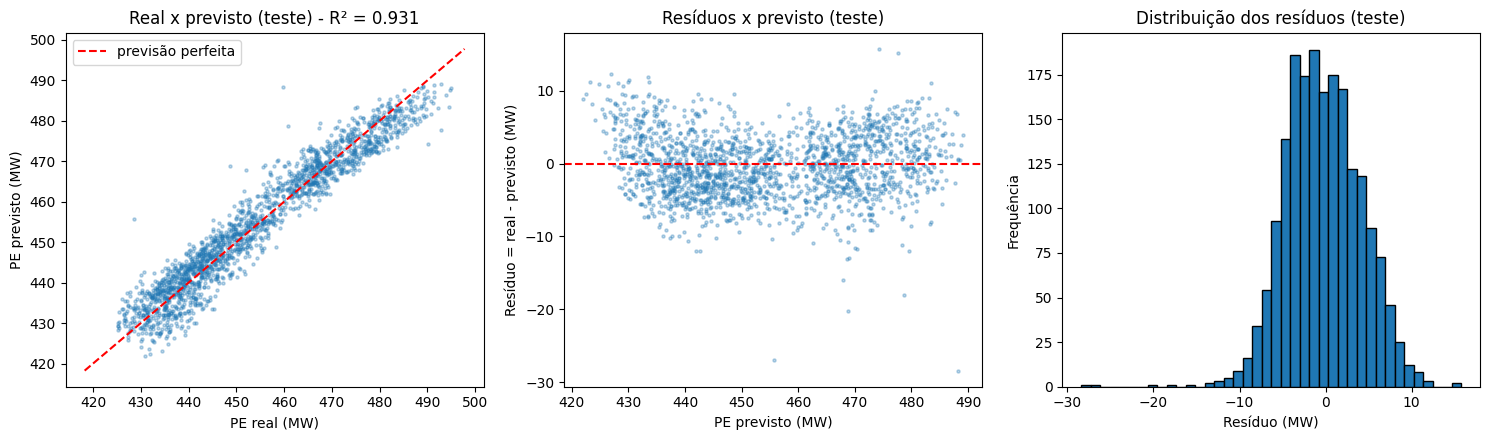

In [26]:
titulo("TAREFA 4 - Avaliação: R2, RMSE e MAE")

y_prev_treino = modelo.predict(X_treino)
y_prev_teste = modelo.predict(X_teste)

# Linha de base: prever sempre a média do treino. Todo modelo útil precisa
# vencer esta referência.
base = DummyRegressor(strategy="mean").fit(X_treino, y_treino)
y_prev_base = base.predict(X_teste)

amplitude = y.max() - y.min()  # faixa de variação de PE (MW)

linhas = {
    "Treino": (y_treino, y_prev_treino),
    "Teste": (y_teste, y_prev_teste),
    "Linha de base (média) - teste": (y_teste, y_prev_base),
}
resumo = pd.DataFrame(
    {
        nome: {
            "R2": r2_score(yr, yp),
            "RMSE (MW)": rmse(yr, yp),
            "MAE (MW)": mean_absolute_error(yr, yp),
        }
        for nome, (yr, yp) in linhas.items()
    }
).T
print(resumo.round(4))

print(f"\nAmplitude de PE no dataset: {amplitude:.2f} MW "
      f"({y.min():.2f} a {y.max():.2f})")
print(f"Desvio padrão de PE: {y.std():.2f} MW | média de PE: {y.mean():.2f} MW")
print(f"RMSE (teste) / amplitude: {rmse(y_teste, y_prev_teste) / amplitude:.2%}")
print(f"MAE  (teste) / média    : {mean_absolute_error(y_teste, y_prev_teste) / y.mean():.2%}")

# Validação cruzada (5 folds) só sobre o treino: mede a estabilidade do R2.
# O pipeline refaz imputação e padronização dentro de cada fold (sem vazamento).
r2_cv = cross_val_score(modelo, X_treino, y_treino, cv=5, scoring="r2")
print(f"\nR2 em validação cruzada 5-fold (treino): {r2_cv.round(4)}")
print(f"  média = {r2_cv.mean():.4f} | desvio padrão = {r2_cv.std():.4f}")

# Análise dos resíduos (erro = real - previsto), no teste
residuos = y_teste.to_numpy() - y_prev_teste
print("\nResíduos no teste:")
print(f"  média = {residuos.mean():+.3f} MW | desvio padrão = {residuos.std():.3f} MW")
print(f"  |erro| máximo = {np.abs(residuos).max():.2f} MW")
for lim in (5, 10):
    print(f"  % das previsões com |erro| <= {lim} MW: "
          f"{(np.abs(residuos) <= lim).mean():.1%}")

# Efeito da multicolinearidade na capacidade de previsão: refaz o modelo
# sem a variável V (a mais correlacionada com AT) e compara no teste.
sem_v = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())
cols_sem_v = [c for c in FEATURES if c != "V"]
sem_v.fit(X_treino[cols_sem_v], y_treino)
p_sem_v = sem_v.predict(X_teste[cols_sem_v])
print("\nExperimento: removendo V (colinear com AT)")
print(f"  R2 = {r2_score(y_teste, p_sem_v):.4f} | RMSE = {rmse(y_teste, p_sem_v):.3f} MW "
      f"| MAE = {mean_absolute_error(y_teste, p_sem_v):.3f} MW")
print(f"  (com as 4 variáveis: R2 = {r2_score(y_teste, y_prev_teste):.4f})")

# Figura 4: real x previsto, resíduos x previsto e histograma dos resíduos
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))

ax = eixos[0]
ax.scatter(y_teste, y_prev_teste, s=5, alpha=0.3)
lim = [y.min() - 2, y.max() + 2]
ax.plot(lim, lim, "r--", label="previsão perfeita")
ax.set_xlabel("PE real (MW)")
ax.set_ylabel("PE previsto (MW)")
ax.set_title(f"Real x previsto (teste) - R² = {r2_score(y_teste, y_prev_teste):.3f}")
ax.legend()

ax = eixos[1]
ax.scatter(y_prev_teste, residuos, s=5, alpha=0.3)
ax.axhline(0, color="red", ls="--")
ax.set_xlabel("PE previsto (MW)")
ax.set_ylabel("Resíduo = real - previsto (MW)")
ax.set_title("Resíduos x previsto (teste)")

ax = eixos[2]
ax.hist(residuos, bins=40, edgecolor="black")
ax.set_xlabel("Resíduo (MW)")
ax.set_ylabel("Frequência")
ax.set_title("Distribuição dos resíduos (teste)")

fig.tight_layout()
fig.savefig(PASTA_FIG / "t4_avaliacao_modelo.png", dpi=150)
plt.show()



# Pelos dados apresentados, e com a interpretação de que um bom R² , seria um R² de teste e treino próximos, podemos concluir que é um bom modelo para essa análise